# Another benchmark on kepler 51 

Major components
- reproduce results from Libby-Roberts 2020 and compare the results with jnkepler

In [1]:
import os
NUM_CHAINS = 2      # parallel MCMC chains (Hamiltonian MC section): one host CPU device per chain
os.environ["XLA_FLAGS"] = (os.environ.get("XLA_FLAGS", "") + f" --xla_force_host_platform_device_count={NUM_CHAINS}").strip()

import sys
sys.path.insert(0, "..")            # the package lives one folder up

import src                      # import Nbody before running anything in jax (CPU runtime setup)
from src import Integrator, Integrator_no_grad, State, get_default_ICs, Integrator_reverse
from src.ics.initial_conditions import ElementsIC
from src.integrator.timing import calc_dtdelements
import jax
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt
import logging
import time
import pandas as pd
from pathlib import Path
from scipy.optimize import minimize
from scipy.special import gammaln

print(jax.devices())

[CpuDevice(id=0), CpuDevice(id=1)]


### Reproduce Kepler-51 TTV

In [2]:
NAMES = list("bcd")
COLORS = plt.cm.tab10(np.arange(3))
TOFF = 155.00
TEND = 2950.00

d = pd.read_csv("./Examples/kep51_transit_times.txt", header=None, sep = ' ',
                names=['tnum', 'tc', 'tcerr', 'dnum', 'planum'])
print(d.head(4))
planet = d.planum.to_numpy(int)
epoch  = d.tnum.to_numpy(int)
tobs = d.tc.to_numpy()
terr = d.tcerr.to_numpy()

print(f"{len(d)} transits:", {NAMES[p-1]: int((planet == p).sum()) for p in range(1, 4)})
print(f"time span: from {d.tc.min():.1f} to {d.tc.max():.1f} ")
tobs_group_p = [jnp.array(d.tc[d.planum==j+1]) for j in range(3)]
terr_group_p = [jnp.array(d.tcerr[d.planum==j+1]) for j in range(3)]

   tnum         tc     tcerr  dnum  planum
0     0  159.11020  0.001280     0       1
1     1  204.26341  0.001051     0       1
2     2  249.41429  0.001569     0       1
3     3  294.57387  0.001810     0       1
53 transits: {'b': 31, 'c': 11, 'd': 11}
time span: from 159.1 to 2945.8 


In [ ]:
base = get_default_ICs("kepler-51")
H = np.asarray(base.epsilon)                       # hierarchy matrix
el_default = np.array(base.elements)
el_default[1:, 5] = np.pi/2
n_planet = len(el_default)  # The number of planets
print(f'# of planets : {n_planet}')
t0   = 155                 # start before the first transit
tmax = 2950  - t0               # integrate past the last observed transit
h    = 1.8

print(f"Current integration time: {tmax:2f}, and the time step is {h: 4f}.")
intr = Integrator.default(h=h, t0=t0, tmax=tmax)
Intr_no_grad = Integrator_no_grad.default(h=h, t0=t0, tmax=tmax)
tt_template = src.create_transit_timing(tmax=tmax, ic=ElementsIC(t0, H, el_default))

FREE = [0, 1, 2, 3, 4]                         # fit m, P, t0, e cosω, e sinω of each planet (ElementsIC index)
JCOL = {0: 6, 1: 0, 2: 1, 3: 2, 4: 3}          # dtdelements element axis

def model_grad(el):
    """Transit times (n, ntt), counts (n,) and d(times)/d(elements) (n, ntt, 7, n)."""
    ic = ElementsIC(t0, H, el)
    s, tt = intr(State.from_ic(ic), tt_template)
    tt = calc_dtdelements(s, tt)
    return np.asarray(tt.tt), np.asarray(tt.count), np.asarray(tt.dtdelements)

def model_no_grad(el):
    """Transit times (n, ntt), counts (n,) """
    ic = ElementsIC(t0, H, el)
    s, tt = Intr_no_grad(State.from_ic(ic), tt_template)
    return np.asarray(tt.tt), np.asarray(tt.count)

start = time.perf_counter()
T_def, C_def, _ = model_grad(el_default)
print(f"first call (includes compilation): {time.perf_counter() - start:.1f} s")
start = time.perf_counter()
T_def, C_def, _ = model_grad(el_default)
print(f"second call: {time.perf_counter() - start:.1f} s. Does it become smaller?")
print(f"transits per planet: {C_def[1:]}")

# of planets : 4
Current integration time: 2795.000000, and the time step is  1.000000.
first call (includes compilation): 3.8 s
second call: 0.1 s. Does it become smaller?
transits per planet: [62 33 22]


In [4]:
offset = {}
for p in range(1, 4):
    sel = planet == p
    nearest = np.array([np.argmin(np.abs(T_def[p, :C_def[p]] - t)) for t in tobs[sel]])
    offset[p] = int(np.round(np.median(nearest - epoch[sel])))
k = epoch + np.array([offset[p] for p in planet])       # model transit index of each observation
print("epoch offsets:", offset)

epoch offsets: {1: 0, 2: 1, 3: 0}


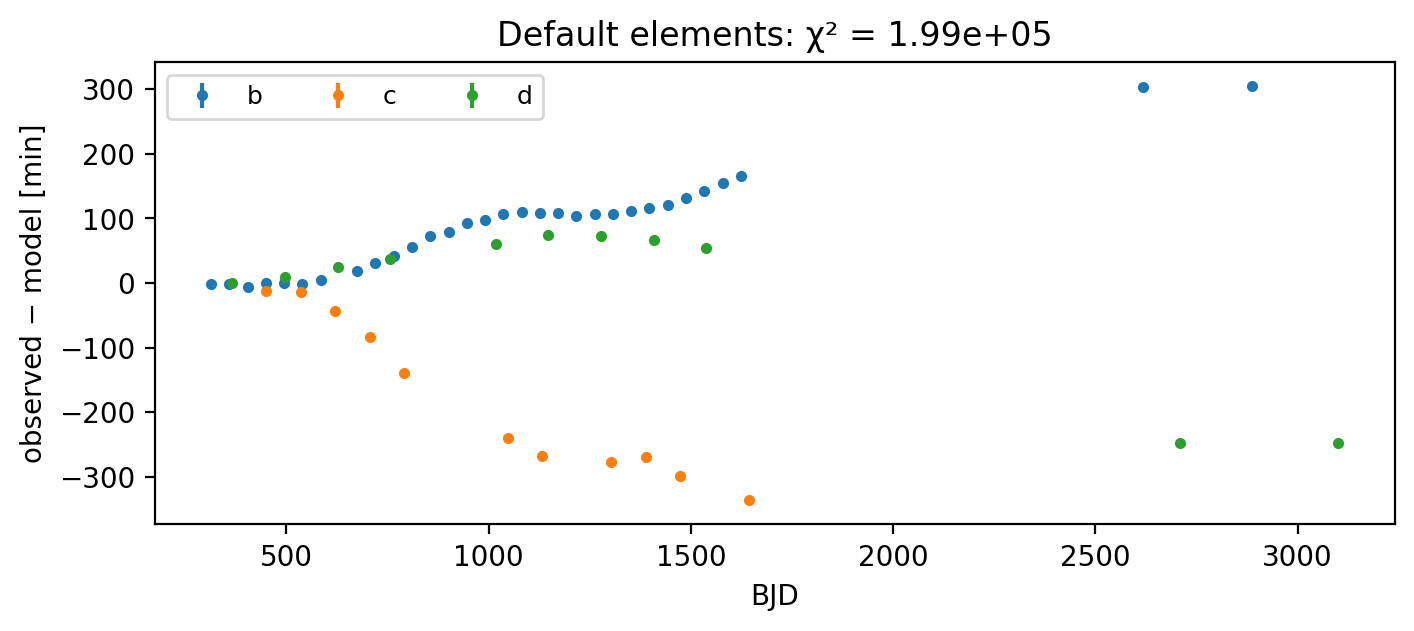

In [5]:
res_def = (tobs - T_def[planet, k]) * 1440            # minutes
fig, ax = plt.subplots(figsize=(8, 3), dpi = 200)
for p in range(1, 4):
    sel = planet == p
    ax.errorbar(tobs[sel] + TOFF, res_def[sel], terr[sel] * 1440, fmt="o", ms=3, color=COLORS[p-1], label=NAMES[p-1])
ax.set(xlabel="BJD", ylabel="observed − model [min]",
       title=f"Default elements: χ² = {np.sum((res_def / (terr * 1440))**2):.3g}")
ax.legend(ncol=7, fontsize=9)
plt.show()

In [6]:
def residuals_only(el):
    T, C = model_no_grad(el)
    if not np.all(k < C[planet]):
        return None
    r = (tobs - T[planet, k]) / terr
    return np.asarray(r)


def residuals_and_jacobian(el):
    T, C, D = model_grad(el)
    if not np.all(k < C[planet]):
        return None, None
    r = (tobs - T[planet, k]) / terr
    J = np.stack([D[planet, k, JCOL[e], b] for b in range(1, 4) for e in FREE], axis=1) / terr[:, None]
    return np.asarray(r), np.asarray(J)

def update(el, dp):
    el = el.copy()
    el[1:, FREE] += dp.reshape(3, len(FREE))
    return el

el = el_default.copy()
lam = 1e-3
r, J = residuals_and_jacobian(el)
chi2 = r @ r
history = [chi2]
print(f"iter 0: chi2 = {chi2:.6g}")
start = time.perf_counter()
init_start = start
# Levenberg-Marquardt algorithm
for it in range(1, 300):
    A, g = J.T @ J, J.T @ r
    while True:
        dp = np.linalg.solve(A + lam * np.diag(np.diag(A)), g) #LM optimization ： X(n+1) = X(n) - (J.T @ J + lambda I)-1 Jr
        el_try = update(el, dp)
        r_try, J_try = residuals_and_jacobian(el_try) 
        chi2_try = np.inf if r_try is None else r_try @ r_try
        if chi2_try < chi2 or lam > 1e8:
            break
        lam *= 10
    if chi2_try >= chi2:
        break
    converged = chi2 - chi2_try < 1e-4 * chi2
    el, r, J, chi2, lam = el_try, r_try, J_try, chi2_try, lam / 10
    history.append(chi2)
    print(f"iter {it}: chi2 = {chi2:.6g}".ljust(35)+ f"with time {time.perf_counter() - start: 1f} seconds")
    start = time.perf_counter()
    if converged:
        break

print(f"fit time {time.perf_counter() - init_start:.1f} s;  chi2 = {chi2:.1f} for {len(r)} transits, {J.shape[1]} parameters ")

cov = np.linalg.inv(J.T @ J)                        # Fisher-matrix covariance at the best fit
sigma = np.sqrt(np.diag(cov)).reshape(3, len(FREE))
el_fit = el

iter 0: chi2 = 199051
iter 1: chi2 = 24104.8             with time  0.062490 seconds
iter 2: chi2 = 6925                with time  0.062294 seconds
iter 3: chi2 = 1204.82             with time  0.064540 seconds
iter 4: chi2 = 539.919             with time  0.244885 seconds
iter 5: chi2 = 127.804             with time  0.124254 seconds
iter 6: chi2 = 92.6108             with time  0.062648 seconds
iter 7: chi2 = 54.6489             with time  0.070847 seconds
iter 8: chi2 = 51.4665             with time  0.129498 seconds
iter 9: chi2 = 49.8249             with time  0.131791 seconds
iter 10: chi2 = 48.927             with time  0.127925 seconds
iter 11: chi2 = 48.4141            with time  0.126761 seconds
iter 12: chi2 = 48.1173            with time  0.128757 seconds
iter 13: chi2 = 47.9464            with time  0.127425 seconds
iter 14: chi2 = 47.8479            with time  0.132828 seconds
iter 15: chi2 = 47.7981            with time  0.064869 seconds
iter 16: chi2 = 47.7156          

In [7]:
def get_parameter_bounds(n_planet, t0_guess=None, p_guess=None,
                                 dtic=0.2, dp_frac=1e-2, emax=0.2,
                                 mmin=1e-7, mmax=1e-3):
    """Get parameter bounds for TTV optimization.

    Args:
        
        n_planets (int, optional): Number of planets.
        t0_guess (array-like, optional): Initial guess for transit times, length must be n_planet.
        p_guess (array-like, optional): Initial guess for orbital periods, length must be n_planet.
        dtic (float, optional): Half-width of bounds around t0_guess for transit time.
        dp_frac (float, optional): Fractional width of bounds around p_guess for period.
        emax (float, optional): Maximum ecosw/esinw bound.
        mmin (float, optional): Minimum mass bound.
        mmax (float, optional): Maximum mass bound.

    Returns:
        dict: Dictionary of parameter bounds with keys as parameter names
            and values as [lower_bound_array, upper_bound_array].
    """

    if t0_guess is None:
        t0_guess = np.array([tobs_[0] for tobs_ in tobs_group_p ])
    else:
        t0_guess = np.array(t0_guess)
    assert len(t0_guess) == n_planet, f"t0_guess length {len(t0_guess)} != n planets {n_planet}"

    if p_guess is None:
        p_guess = np.array(el_default[1:, 1])
    else:
        p_guess = np.array(p_guess)
    assert len(p_guess) == n_planet, f"p_guess length {len(p_guess)} != n_planets: {n_planet}"

    ones = np.ones(n_planet)
    param_bounds = {
        "t0": [t0_guess - dtic, t0_guess + dtic],
        "P": [p_guess * (1 - dp_frac), p_guess * (1 + dp_frac)],
        "ecos_omega": [-emax * ones, emax * ones],
        "esin_omega": [-emax * ones, emax * ones],
        "lnmass": [np.log(mmin) * ones, np.log(mmax) * ones],
        "mass": [mmin * ones, mmax * ones],
    }
    return param_bounds

param_bounds = get_parameter_bounds(n_planet - 1) #other than the star
param_bounds

{'t0': [array([158.9102 , 295.11635, 211.82419]),
  array([159.3102 , 295.51635, 212.22419])],
 'P': [array([ 44.702658,  84.461157, 128.883348]),
  array([ 45.605742,  86.167443, 131.487052])],
 'ecos_omega': [array([-0.2, -0.2, -0.2]), array([0.2, 0.2, 0.2])],
 'esin_omega': [array([-0.2, -0.2, -0.2]), array([0.2, 0.2, 0.2])],
 'lnmass': [array([-16.11809565, -16.11809565, -16.11809565]),
  array([-6.90775528, -6.90775528, -6.90775528])],
 'mass': [array([1.e-07, 1.e-07, 1.e-07]), array([0.001, 0.001, 0.001])]}

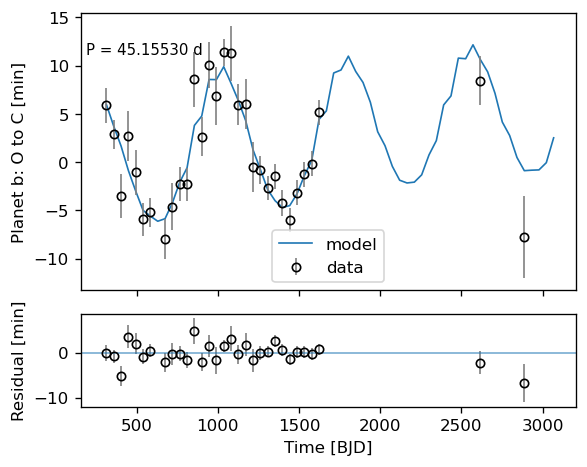

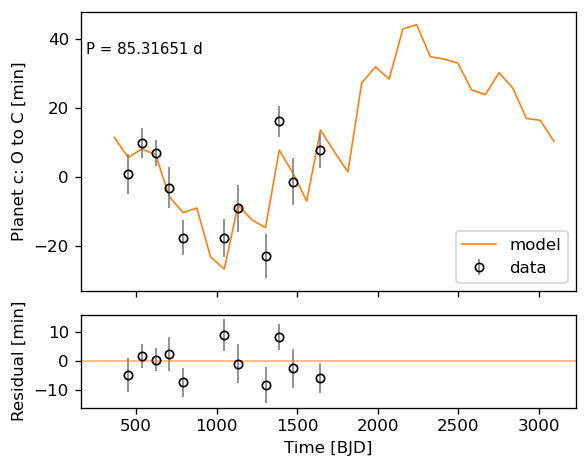

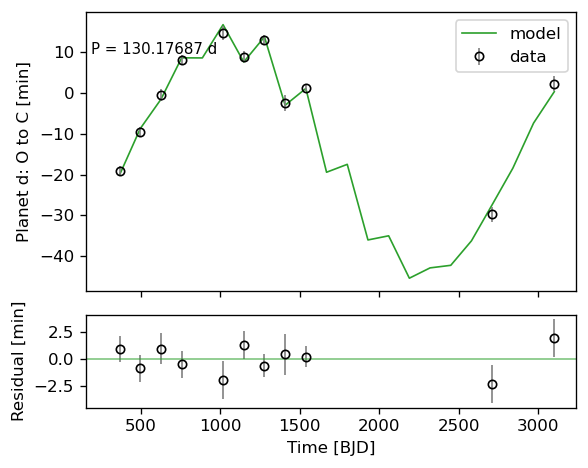

In [8]:
T_fit, C_fit, _ = model_grad(el_fit)
res_fit = (tobs - T_fit[planet, k]) * 1440
for p in range(1, 4):
    fig, (ax1, ax2) = plt.subplots(2,1, figsize = (5, 4),dpi = 120, sharex = True, gridspec_kw= {'height_ratios': [3,1]})

    sel = planet == p
    w = 1 / terr[sel]**2
    P_lin, T0_lin = np.polyfit(k[sel], tobs[sel], 1, w=np.sqrt(w)) #orbital period and reference transit time, T = T0 + Pn
    n_all = np.arange(C_fit[p])
    n_all = n_all[T_fit[p, n_all] + TOFF >= 155]

    ax1.plot(T_fit[p, n_all] + TOFF, (T_fit[p, n_all] - (T0_lin + P_lin * n_all)) * 1440, "-", color=COLORS[p-1], lw=1, label = 'model')
    ax1.errorbar(tobs[sel] + TOFF, (tobs[sel] - (T0_lin + P_lin * k[sel])) * 1440, terr[sel] * 1440,
                fmt="o", ms=5, color="k", ecolor="0.5", lw=1, label = 'data', mfc='none')
    ax1.set_ylabel(f"Planet {NAMES[p-1]}: O to C [min]")
    ax1.set_xlim(left = 155)
    ax1.text(0.01, 0.85, f"P = {P_lin:.5f} d", transform=ax1.transAxes, fontsize=9)
    ax1.legend()

    ax2.errorbar(tobs[sel] + TOFF, res_fit[sel], terr[sel] * 1440, fmt="o", ms=5, color='k',ecolor="0.5", mfc='none', lw=1,label=NAMES[p-1])
    ax2.axhline(0, c = COLORS[p-1], lw = 1, alpha = 0.6)
    ax2.set_ylabel("Residual [min]")
    ax2.set_xlabel("Time [BJD]")
    
    plt.tight_layout()
    plt.show()

### Check residuals

In [9]:
import numpyro
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, init_to_value
from jax import random, config 
from scipy import special
from scipy.stats import norm
from scipy.stats import t as tdist

In [10]:
def _knuth_bin_width(x, Mmax=200, return_bins=False):
    """
    Compute optimal histogram bin width using Knuth (2006) rule with a
    Freedman-Diaconis lower bound.

    The function performs a discrete search over the number of bins
    M = 1..min(Mmax, N) and selects the value that maximizes the
    Knuth log-posterior. A Freedman-Diaconis floor ensures a
    reasonable binning even for pathological distributions.

    Args:
        x (array_like): 
            1D input data array. Must be finite and non-empty.
        Mmax (int, optional): 
            Maximum number of bins to consider in the Knuth search.
            Defaults to 200 (or N if smaller).
        return_bins (bool, optional): 
            If True, also return the computed bin edges.

    Returns:
        float or tuple:
            If `return_bins` is False, returns the optimal bin width (`float`).
            If `return_bins` is True, returns a tuple `(width, bins)` where:
                - `width` (`float`): Optimal bin width.
                - `bins` (`ndarray`): Array of bin edges.
    """
    x = np.asarray(x, float).ravel()
    if x.size == 0 or not np.isfinite(x).all():
        raise ValueError("x must be finite and non-empty")
    x.sort()
    n = x.size
    xmin, xmax = x[0], x[-1]

    # all identical -> trivial
    if xmax == xmin:
        w = 1.0
        return (w, np.array([xmin - 0.5, xmax + 0.5])) if return_bins else w

    # --- Freedman–Diaconis bins (floor) ---
    q25, q75 = np.percentile(x, [25, 75])
    iqr = q75 - q25
    if iqr <= 0:
        M_fd = max(1, int(np.sqrt(n)))
    else:
        dx_fd = 2.0 * iqr / (n ** (1/3))
        M_fd = max(1, int(np.ceil((xmax - xmin) / dx_fd))) if dx_fd > 0 else 1

    # --- Knuth discrete search ---
    Mmax = int(max(1, min(Mmax, n)))
    best_val, best_M = -np.inf, 1
    for M in range(1, Mmax + 1):
        bins = np.linspace(xmin, xmax, M + 1)  # match astropy's choice
        nk, _ = np.histogram(x, bins=bins)
        val = (n * np.log(M)
            + special.gammaln(0.5 * M)
            - M * special.gammaln(0.5)
            - special.gammaln(n + 0.5 * M)
            + np.sum(special.gammaln(nk + 0.5))
        )
        if val > best_val:
            best_val, best_M = val, M

    M = max(best_M, M_fd)
    bins = np.linspace(xmin, xmax, M + 1)
    w = bins[1] - bins[0]
    return (w, bins) if return_bins else w


In [11]:
def fit_t_distribution(y, plot = True, fit_mean = False, save = None, xrange =5):
    def model(y):
        logdf = numpyro.sample(
            "lndf", dist.Uniform(jnp.log(0.1), jnp.log(100)))
        logvar = numpyro.sample("lnvar", dist.Uniform(-2, 10))
        df = numpyro.deterministic("df", jnp.exp(logdf))
        v1 = numpyro.deterministic("v1", jnp.exp(logvar))
        if fit_mean:
            mean = numpyro.sample("mean", dist.Uniform(-jnp.std(y), jnp.std(y)))
            numpyro.sample("obs", dist.StudentT(loc=mean, scale=jnp.sqrt(v1), df=df), obs=y)
        else:
            numpyro.sample("obs", dist.StudentT(scale=jnp.sqrt(v1), df=df), obs=y)

    kernel = numpyro.infer.NUTS(model)
    mcmc = numpyro.infer.MCMC(kernel, num_warmup=500, num_samples=500)
    rng_key = random.PRNGKey(0)
    mcmc.run(rng_key, y)
    mcmc.print_summary()

    samples = mcmc.get_samples()
    lndf, lnvar = np.mean(samples['lndf']), np.mean(samples['lnvar'])
    lndf_sd, lnvar_sd = np.std(samples['lndf']), np.std(samples['lnvar'])
    pout = {'lndf_loc': lndf, 'lndf_scale': lndf_sd,'lnvar_loc': lnvar, 'lnvar_scale': lnvar_sd}
    if fit_mean:
        mean, mean_sd = np.mean(samples['mean']), np.std(samples['mean'])
        pout['mean_loc'] = mean
        pout['mean_scale'] = mean_sd
    else:
        mean = 0.

    if plot:
        xrange = 5
        sd = np.std(y)
        fig, ax = plt.subplots(1, 2, figsize=(16, 4))
        ax[1].set_yscale("log")
        ax[1].set_ylabel("PDF")
        ax[0].set_ylabel("CDF")
        ax[0].set_xlabel("residual / assigned error")
        ax[1].set_xlabel("residual / assigned error")

        bin_width = _knuth_bin_width(y)
        bins = int(np.ceil((y.max() - y.min()) / bin_width))

        ax[1].hist(y, histtype='step', lw=3, alpha=0.6, bins=bins,
                    density=True, color='gray')
        ymin, ymax = plt.gca().get_ylim()
        ax[1].set_ylim(ymin/5., ymax*1.5)
        x0 = np.linspace(-xrange, xrange, 100)
        ax[1].plot(x0, norm(scale=sd).pdf(x0), lw=1, color='C0', ls='dashed',
                    label=r'normal, $\mathrm{SD}=%.2f$' % sd)
        ax[1].plot(x0, norm.pdf(x0), lw=1, color='C0', ls='dotted',
                    label=r'normal, $\mathrm{SD}=1$')
        ax[1].plot(x0, tdist(loc=mean, scale=np.exp(lnvar*0.5), df=np.exp(lndf)).pdf(x0),
                    label=r'Student\'s t\n(lndf=%.2f, lnvar=%.2f, mean=%.2f)' % (lndf, lnvar, mean))

        ysum = np.ones_like(y)
        hist, edge = np.histogram(y, bins=len(y))
        ax[0].plot(np.r_[x0[0], edge[0], edge[:-1], edge[-1], x0[-1]],
                    np.r_[0, 0, np.cumsum(hist)/len(y), 1, 1], lw=3, alpha=0.6, color='gray')
        ax[0].plot(x0, norm(loc=0, scale=sd).cdf(x0), lw=1, color='C0', ls='dashed',
                    label=r'normal, $\mathrm{SD}=%.2f$' % sd)
        ax[0].plot(x0, norm.cdf(x0), lw=1, color='C0', ls='dotted',
                    label=r'normal, $\mathrm{SD}=1$')
        ax[0].plot(x0, tdist(loc=mean, scale=np.exp(lnvar*0.5), df=np.exp(lndf)).cdf(x0),
                    label=r'Student t (lndf=%.2f, lnvar=%.2f, mean=%.2f)' % (lndf, lnvar, mean))
        ax[0].legend(loc='upper left', fontsize=14)
    return pout


(53,) (53,)


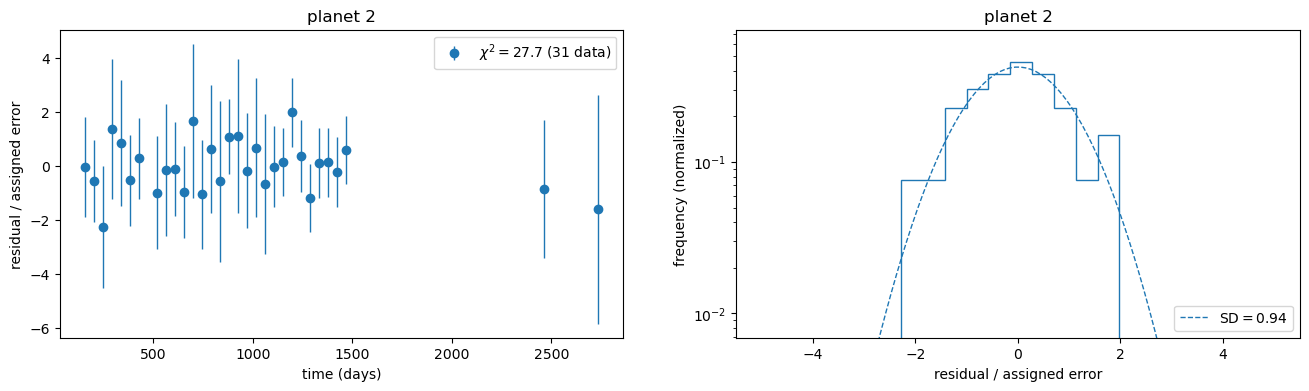

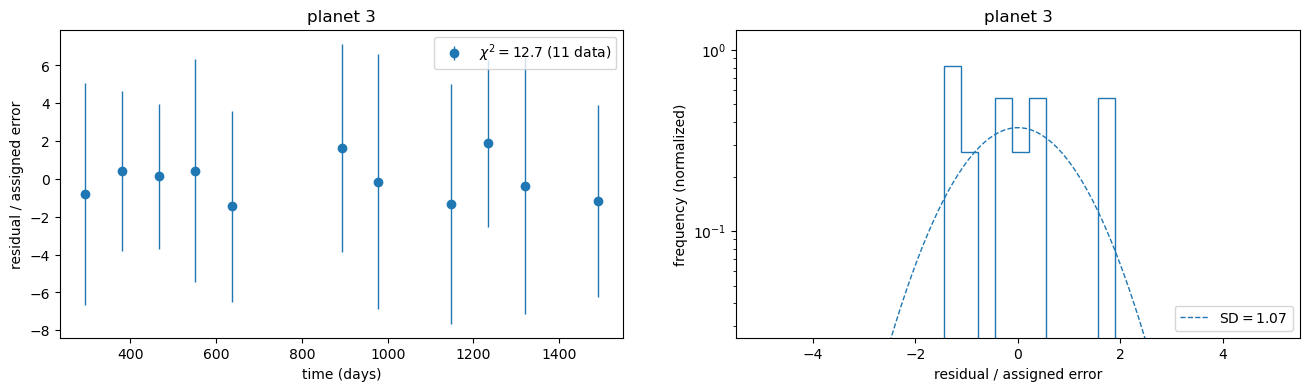

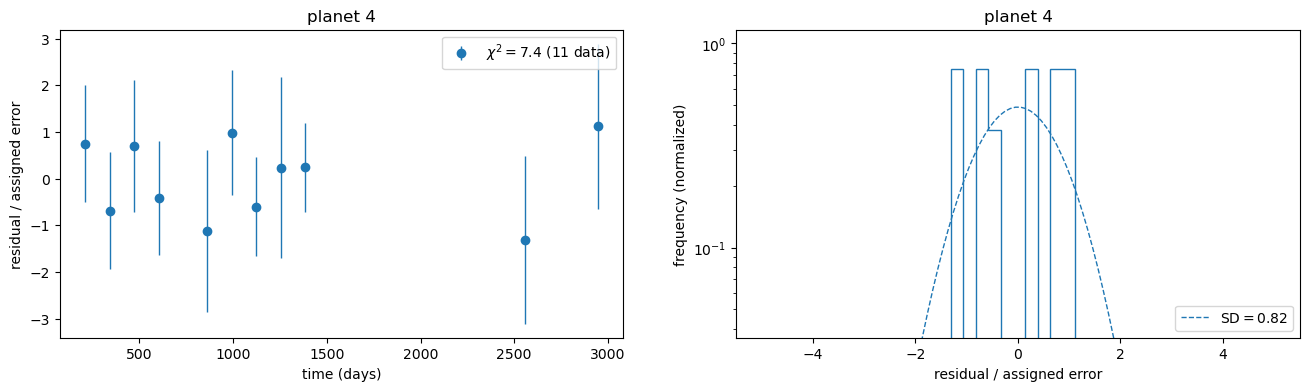

sample: 100%|██████████| 1000/1000 [00:00<00:00, 1366.08it/s, 7 steps of size 5.32e-01. acc. prob=0.81]



                mean       std    median      5.0%     95.0%     n_eff     r_hat
      lndf      3.11      0.93      3.18      1.74      4.61    121.21      1.00
     lnvar     -0.18      0.27     -0.18     -0.53      0.26     51.11      1.01
      mean     -0.04      0.13     -0.04     -0.22      0.22    372.19      1.00

Number of divergences: 0
mean:-0.2546359378700216 sd: 3.1555732296972416; and params_st : {'lndf_loc': Array(3.10831961, dtype=float64), 'lndf_scale': Array(0.92922611, dtype=float64), 'lnvar_loc': Array(-0.1811772, dtype=float64), 'lnvar_scale': Array(0.26786975, dtype=float64), 'mean_loc': Array(-0.03898043, dtype=float64), 'mean_scale': Array(0.1331999, dtype=float64)}


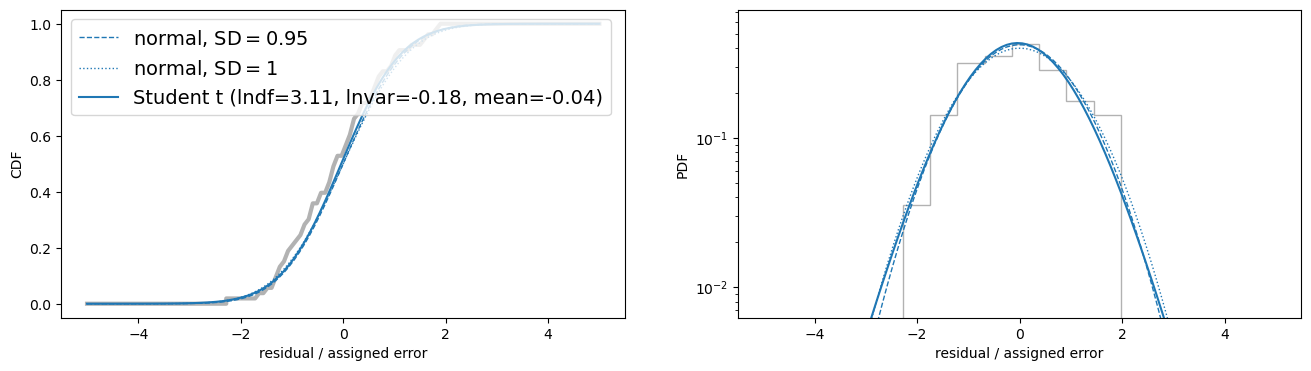

In [12]:
xrange = 5
res_all = tobs - T_fit[planet, k]
y_all = res_all / terr #normalize the residuals

print(terr.shape, res_fit.shape)
#errorbar(tobs[sel] + TOFF, res_fit[sel], terr[sel] * 1440, 
for j in range(1, n_planet):
    sel = planet == j
    y = y_all[sel]
    fig, ax = plt.subplots(1, 2, figsize=(16, 4))
    ax[0].errorbar(tobs[sel], y,  yerr= terr[sel]*1440, fmt='o', lw=1,
                    label=r'$\chi^2=%.1f$ (%d data)' % (np.sum(y**2), len(y)))
    ax[0].set_ylabel('residual / assigned error')

    ax[0].set_title("planet %d" % (j+1))
    ax[0].set_xlabel("time (days)")
    ax[0].legend(loc='best')

    sd = np.std(y)
    ax[1].set_yscale("log")
    ax[1].hist(y, histtype='step', lw=1, density=True, color='C0')
    ymin, ymax = ax[1].get_ylim()

    ax[1].set_ylim(ymin/10, ymax*1.5)
    ax[1].set_title("planet %d" % (j+1))
    ax[1].set_xlabel("residual / assigned error")
    ax[1].set_ylabel('frequency (normalized)')
    
    x0 = np.linspace(-xrange, xrange, 100)
    ax[1].plot(x0, np.exp(-0.5*x0**2/sd**2)/np.sqrt(2*np.pi)/sd, lw=1, color='C0',
                ls='dashed', label=r'$\mathrm{SD}=%.2f$' % (sd))
    ax[1].legend(loc='lower right')
    plt.show()

# Student's t fit

params_st = fit_t_distribution(y_all, plot=True, fit_mean=True, save = False, xrange=xrange)

print(f'mean:{np.mean(res_fit)} sd: {np.std(res_fit)}; and params_st : {params_st}')
pdic_normal, pdic_student = np.mean(res_fit), np.std(res_fit)

### HMC

In [ ]:
from dataclasses import replace

to_xvm = src.elements_to_xvm(t0, H)                      # elements -> (x, v, m), differentiable
intr_rev = Integrator_reverse.default(h=h, t0=t0, tmax=tmax)
s_template = State.from_ic(ElementsIC(t0, H, el_fit))
el_base = jnp.asarray(el_fit)                            # I and Omega (not sampled) come from here
planet_jax, k_jax = jnp.asarray(planet), jnp.asarray(k)

def get_transit_times(par):
    """sampled parameters (each (3,)) -> model transit times at the 53 observed epochs"""
    el = (el_base.at[1:, 0].set(par["mass"]).at[1:, 1].set(par["P"]).at[1:, 2].set(par["t0"])
                 .at[1:, 3].set(par["ecos_omega"]).at[1:, 4].set(par["esin_omega"]))
    x, v, m = to_xvm(el)
    _, tt = intr_rev(replace(s_template, x=x, v=v, m=m), tt_template, slots=(planet_jax, k_jax))
    kk = jnp.minimum(k_jax, tt.count[planet_jax] - 1)    # safe index if a transit goes missing
    return tt.tt[planet_jax, kk]                         # (53,)

In [14]:
sample_keys = ['mass', 'P', 't0', 'ecos_omega', 'esin_omega']

def model_indep_normal(sample_keys, param_bounds, uniform_ecc=True, eps=1e-7):
    """numpyro model"""
    par = {}

    # sample parameters from priors
    for key in sample_keys:
        par[key] = numpyro.sample(key, dist.Uniform(param_bounds[key][0], param_bounds[key][1]))
    
    # Jacobian for uniform ecc prior
    # eps is introduced to prevent the log singularity at e=0; a smaller value can be used if needed
    if uniform_ecc:
        # record ecc by numpyro.deterministic
        ecc = numpyro.deterministic("ecc", jnp.sqrt(par['ecos_omega']**2 + par['esin_omega']**2))
        numpyro.factor("eprior", -jnp.log(ecc + eps))

    # compute transit times
    tcmodel = numpyro.deterministic("tcmodel", get_transit_times(par))
    numpyro.sample("obs", dist.Normal(loc=tcmodel, scale=terr), obs=tobs)

In [15]:
rng_key = random.PRNGKey(0)
# Run MCMC with NUTS
init_values = {"mass": el_fit[1:, 0], "P": el_fit[1:, 1], "t0": el_fit[1:, 2],
               "ecos_omega": el_fit[1:, 3], "esin_omega": el_fit[1:, 4]}

kernel = NUTS(model_indep_normal, max_tree_depth=8, target_accept_prob=0.8,
              dense_mass=True, init_strategy=init_to_value(values=init_values))


In [16]:
mcmc = MCMC(kernel, num_warmup= 1000, num_samples= 1000, num_chains= NUM_CHAINS)

In [17]:
mcmc.run(rng_key, sample_keys, param_bounds) #use the fresh, independent randomness

  0%|          | 0/2000 [00:00<?, ?it/s]

  0%|          | 0/2000 [00:00<?, ?it/s]

In [18]:
mcmc.print_summary()


                   mean       std    median      5.0%     95.0%     n_eff     r_hat
         P[0]     45.15      0.00     45.15     45.15     45.15    372.73      1.00
         P[1]     85.31      0.00     85.31     85.31     85.32    371.54      1.00
         P[2]    130.18      0.00    130.18    130.18    130.19    471.01      1.01
ecos_omega[0]      0.02      0.01      0.02      0.01      0.03    497.30      1.00
ecos_omega[1]     -0.01      0.01     -0.00     -0.02      0.01    261.68      1.01
ecos_omega[2]     -0.00      0.01      0.00     -0.02      0.01    269.23      1.01
esin_omega[0]      0.02      0.01      0.02      0.00      0.04    166.52      1.00
esin_omega[1]      0.01      0.01      0.00     -0.01      0.03    164.19      1.01
esin_omega[2]      0.00      0.01      0.00     -0.01      0.02    154.37      1.00
      mass[0]      0.00      0.00      0.00      0.00      0.00    373.79      1.01
      mass[1]      0.00      0.00      0.00      0.00      0.00    291.75  

In [31]:
import arviz as az
import corner as corner
with numpyro.validation_enabled(False):
    idata = az.from_numpyro(mcmc, log_likelihood=True)
#idata.to_netcdf("kep51_ttv_normal.nc")

In [ ]:
# load chains
# idata = az.from_netcdf("kep51_ttv_normal.nc")

### Plot models drawn from posterior

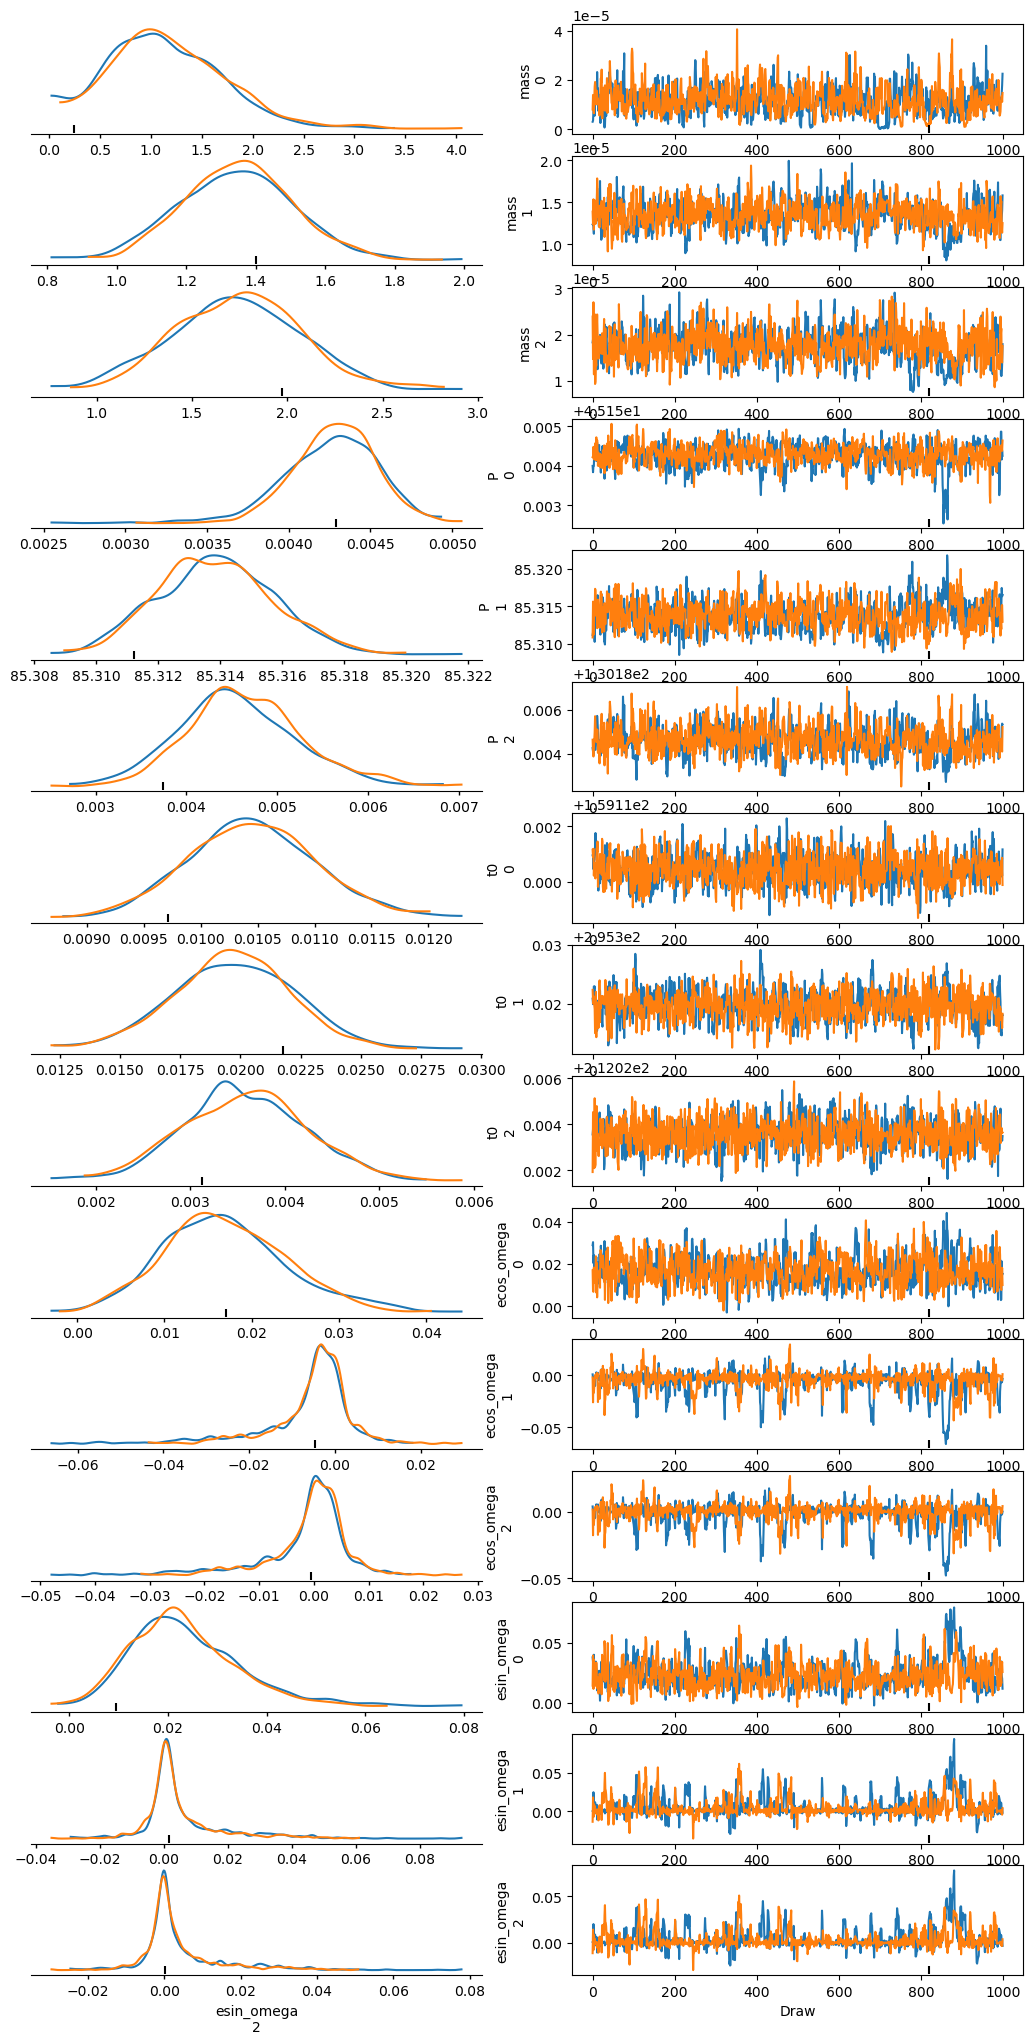

In [28]:
# compute mean and SD of posterior models
fig = az.plot_trace_dist(idata, var_names=sample_keys, compact=False)


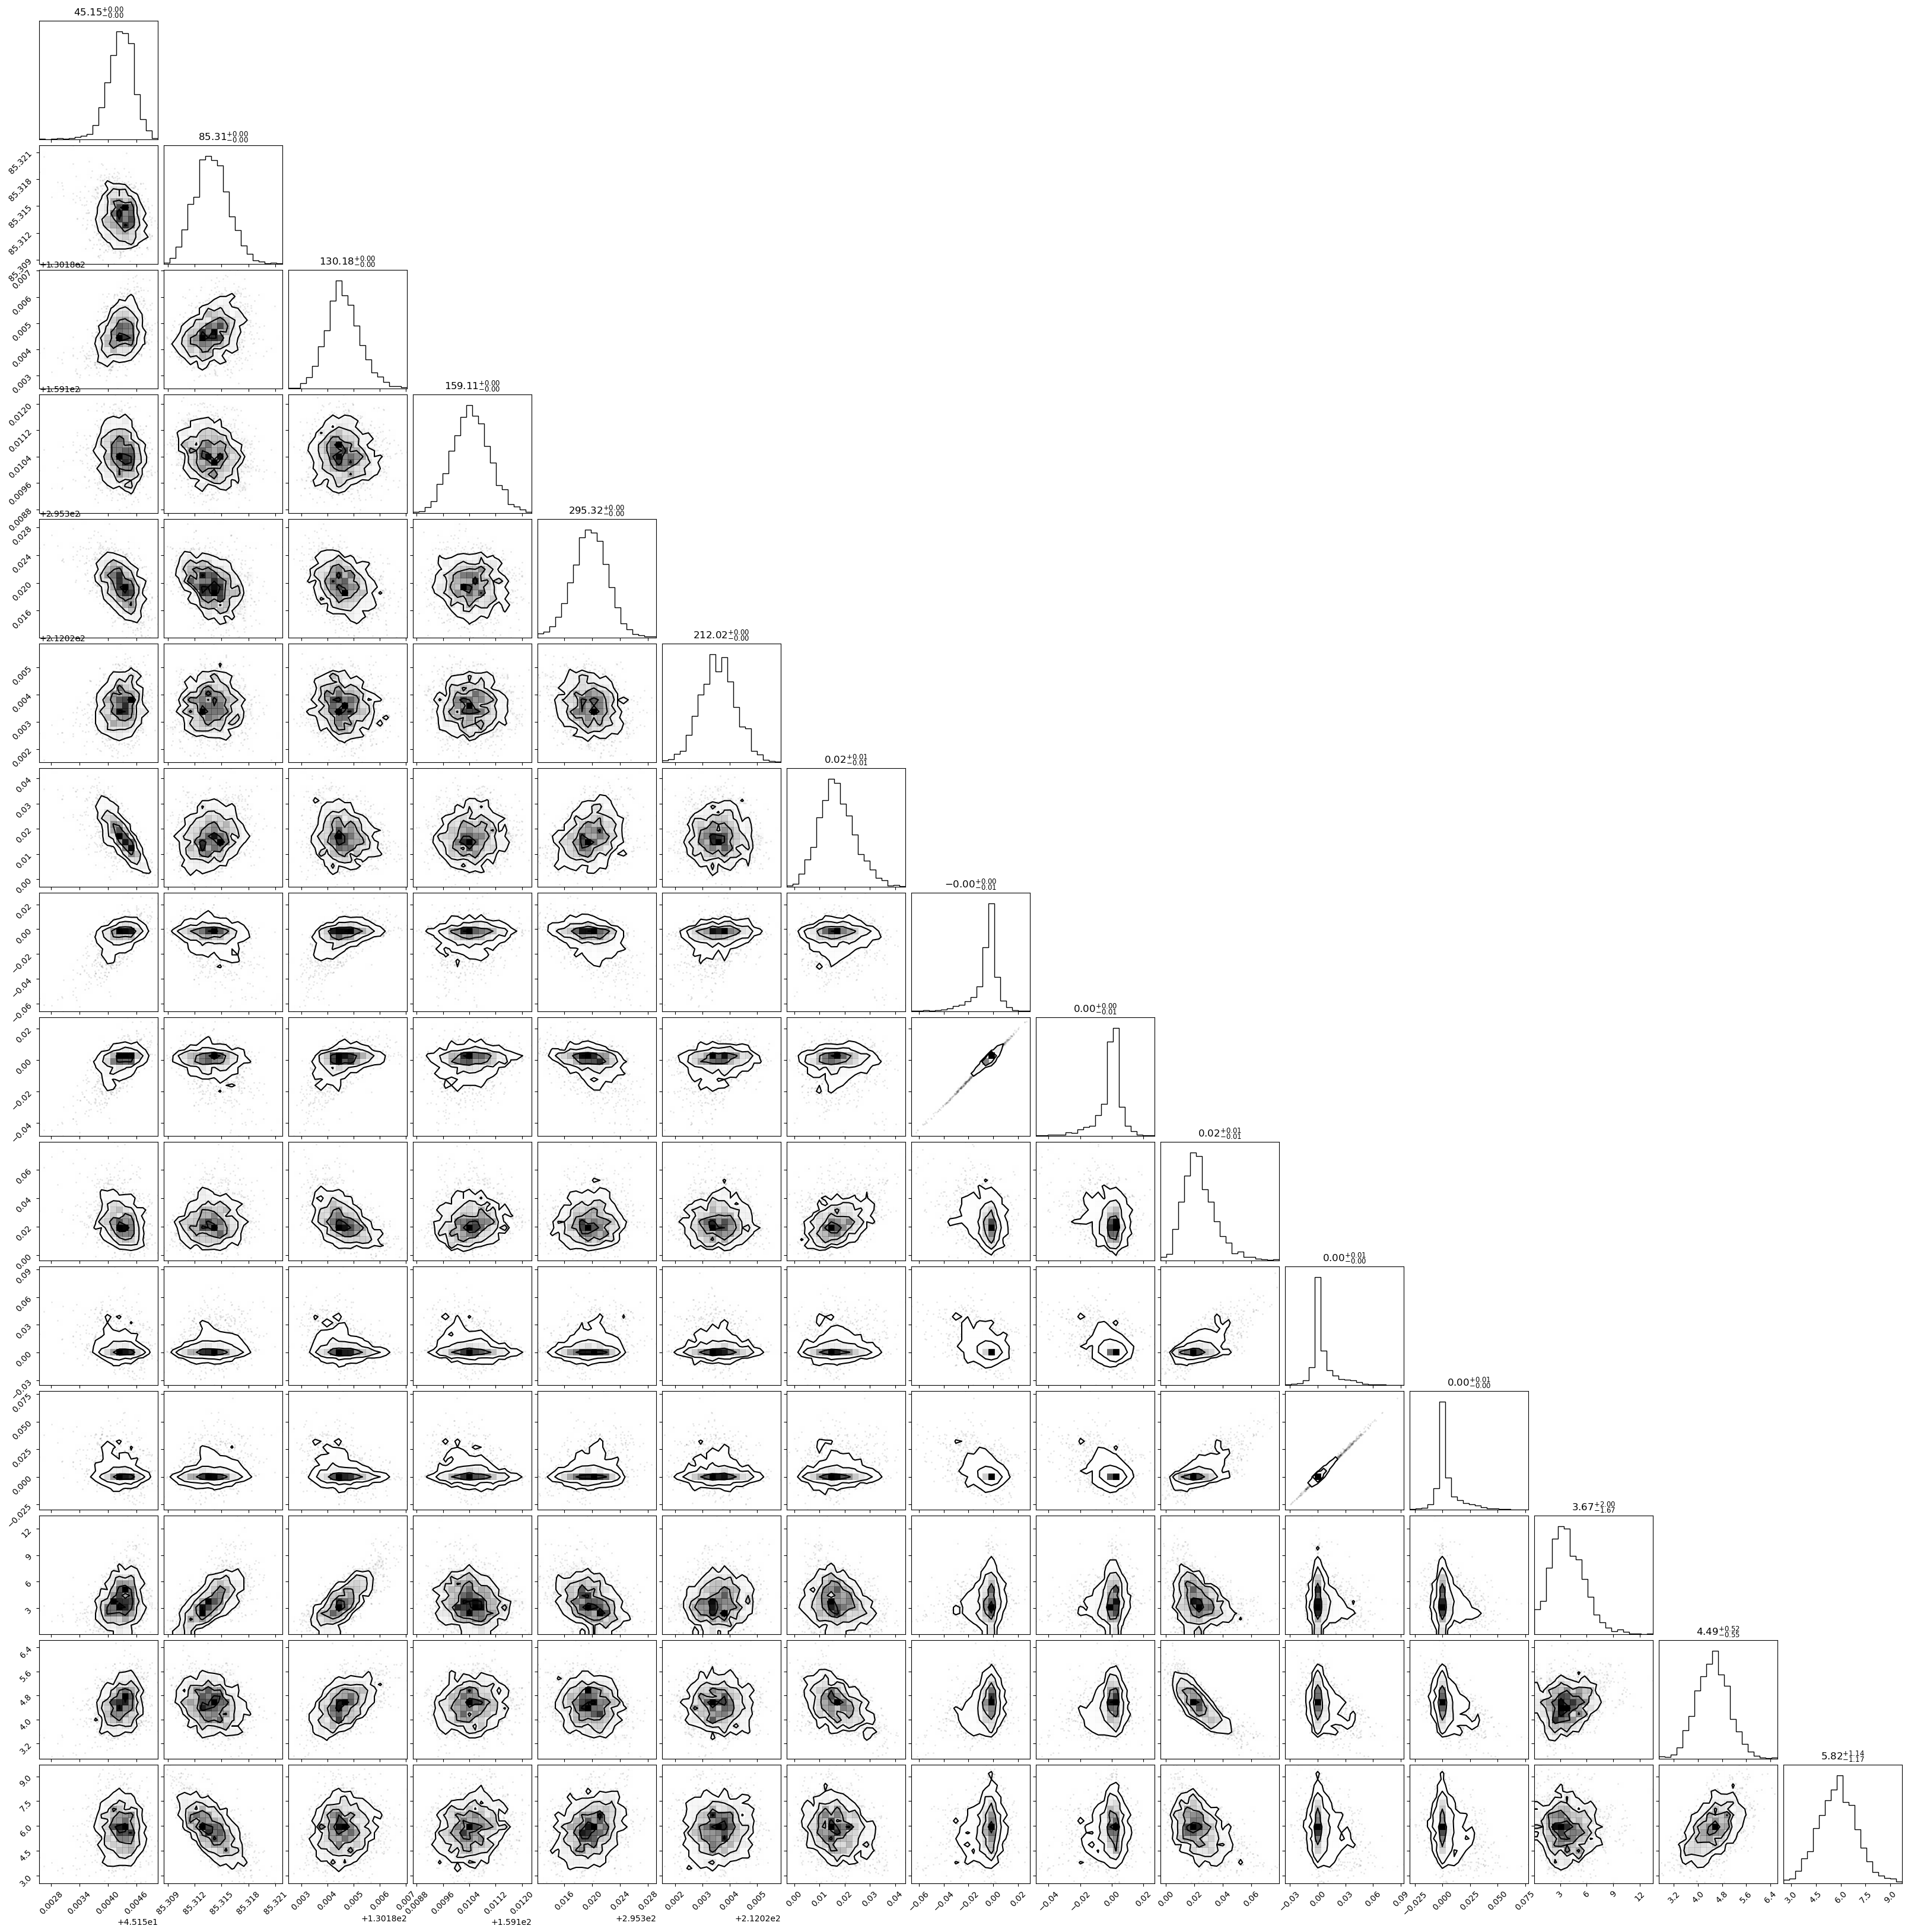

In [46]:
idata.posterior['m'] = idata.posterior['mass'] / 3.003e-6 # Earth mass
names = ["P", "t0", "ecos_omega", "esin_omega", "m"]
post = idata.posterior
flat = np.column_stack([post[k].values[:, :, j].reshape(-1) for k in names for j in range(3)])
fig = corner.corner(flat, var_names=names, show_titles= True)


### Compare with posterior samples from Libby-Roberts + 2020

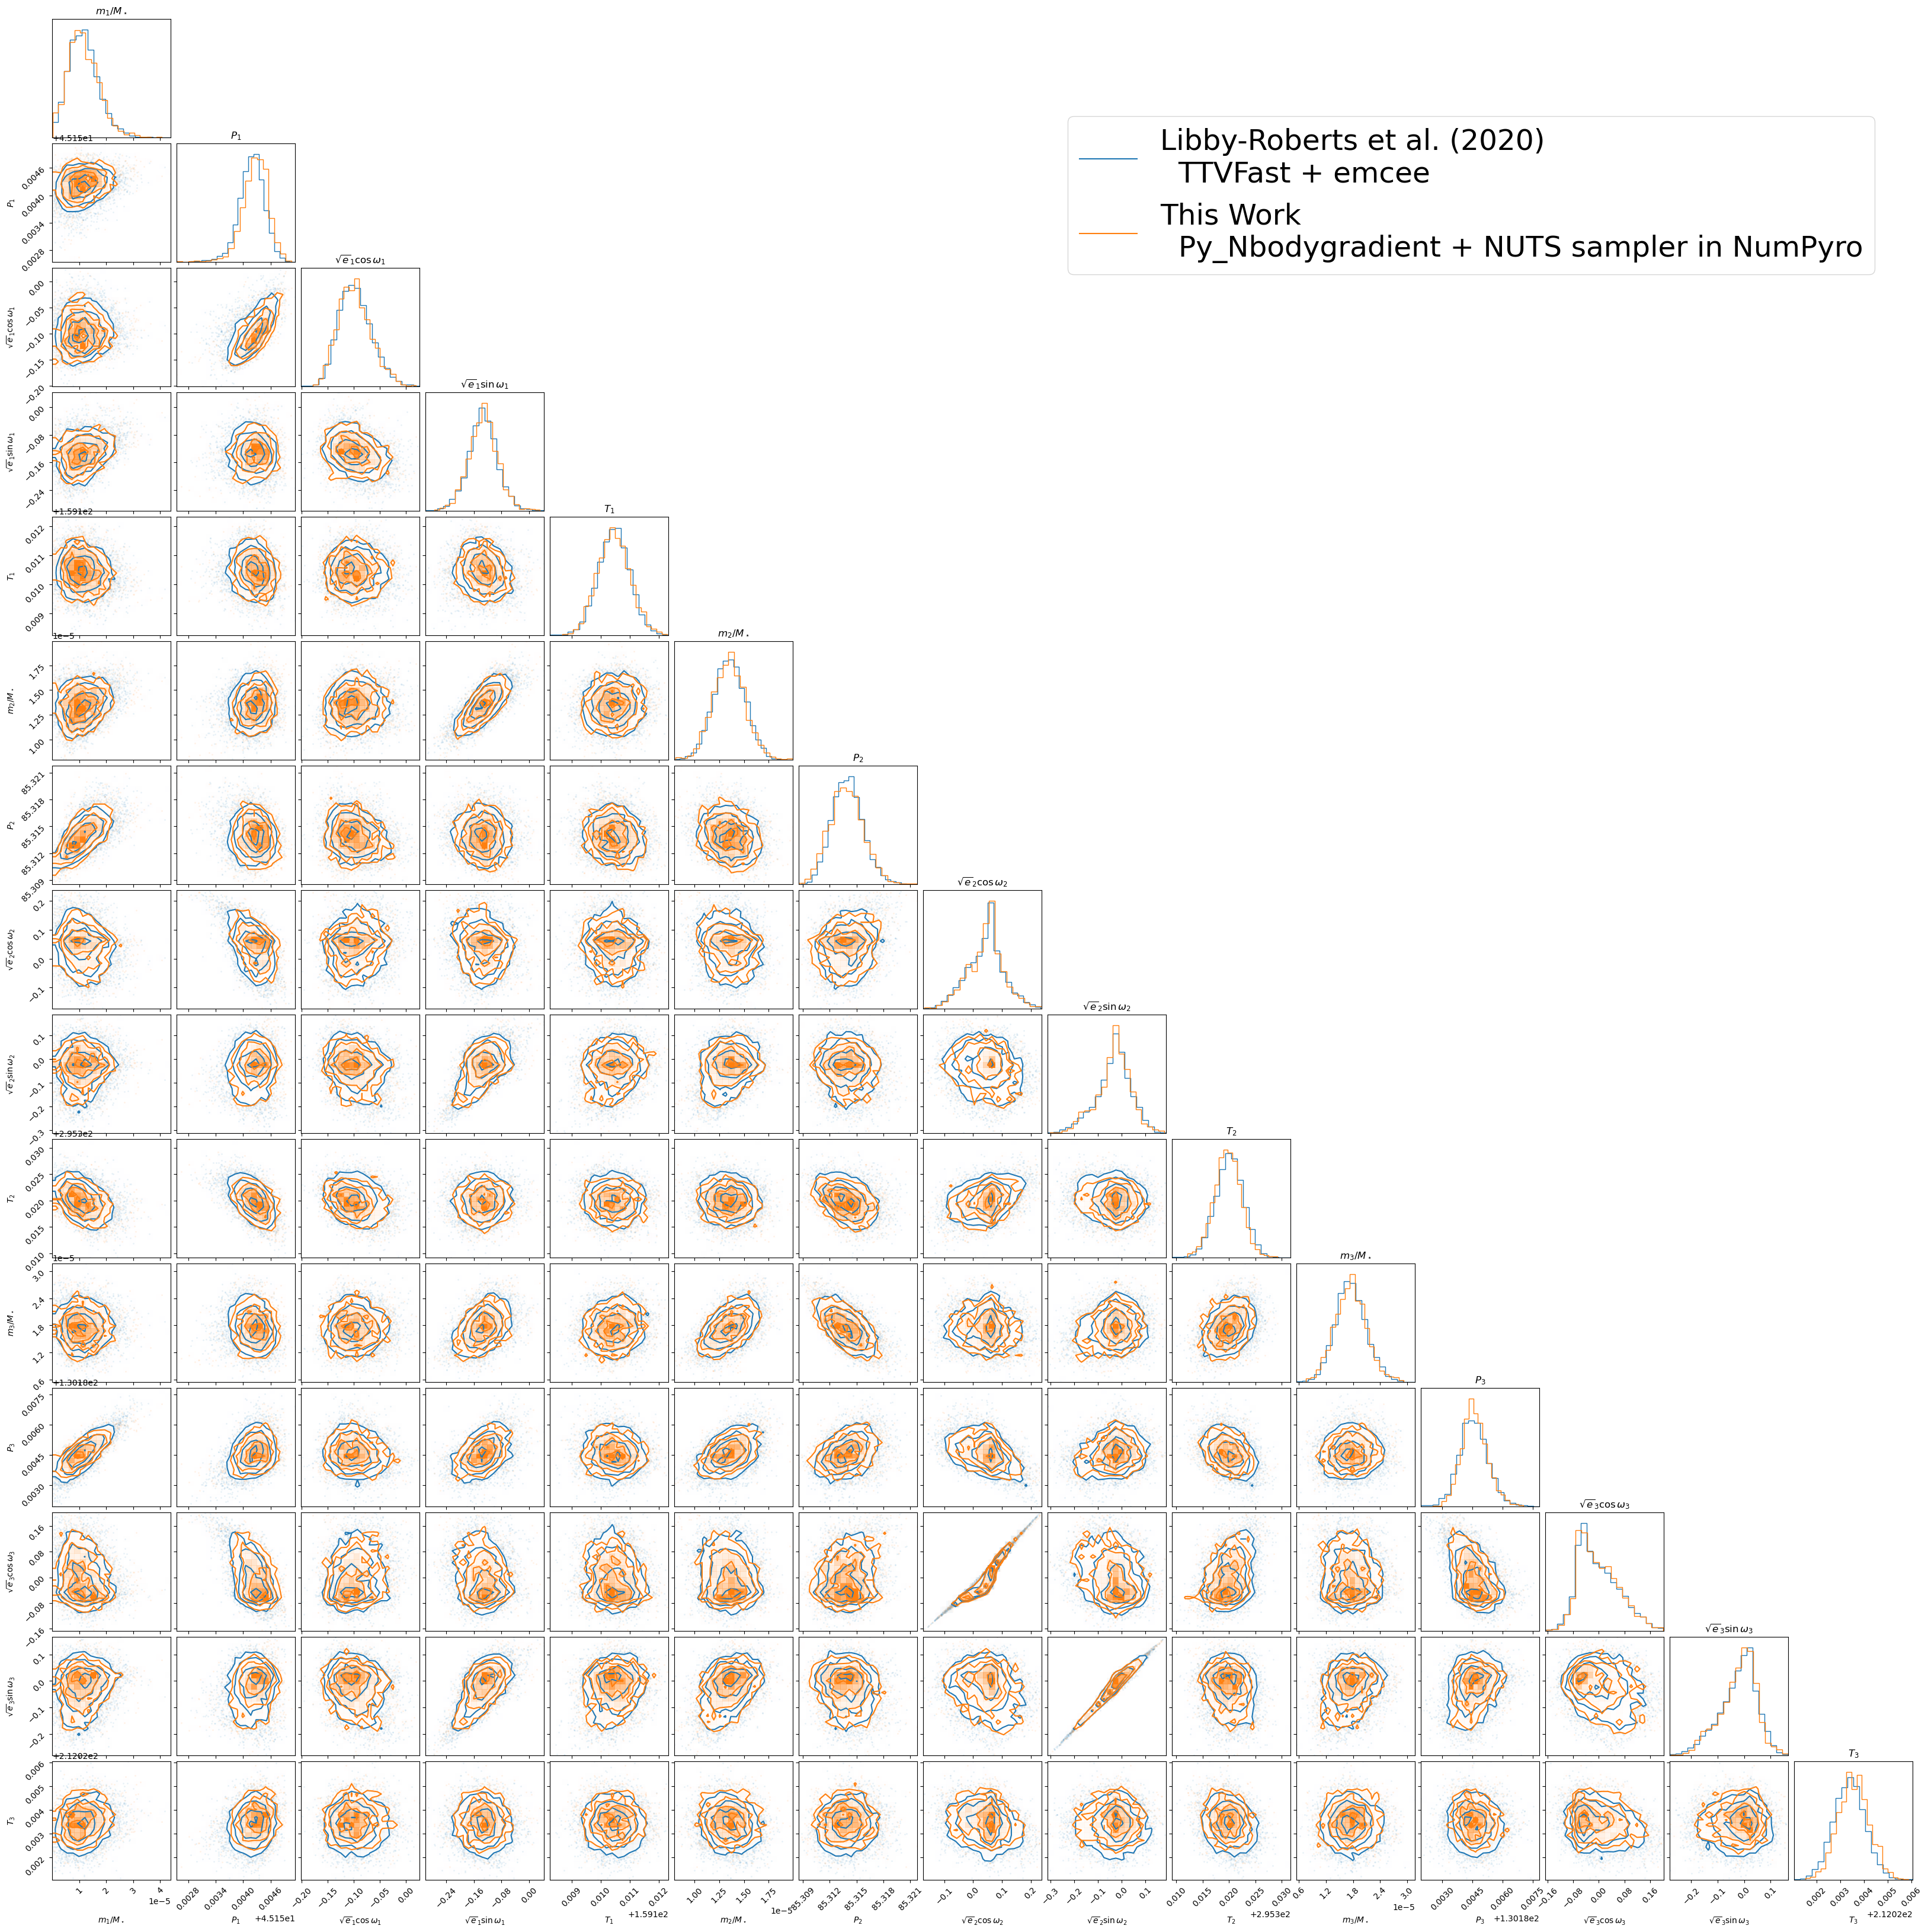

In [50]:
import matplotlib.lines as mlines

def check_corner(mcmc):
    hmc = mcmc.get_samples()
    hmc['ecc'] = np.sqrt(hmc['ecos_omega']**2 + hmc['esin_omega']**2)
    hmc['omega'] = np.arctan2(hmc['esin_omega'], hmc['ecos_omega']) + np.pi
    hmc['ec'] = np.sqrt(hmc['ecc']) * np.cos(hmc['omega'])
    hmc['es'] = np.sqrt(hmc['ecc']) * np.sin(hmc['omega'])
    hmcsmp = np.r_[[[hmc['mass'][:,i], hmc['P'][:,i], hmc['ec'][:,i], hmc['es'][:,i], hmc['t0'][:,i]] for i in range(3)]].reshape(15, -1).T

    emc = pd.read_csv("./Examples/kep51_emcee.tsv", comment='#', delimiter='|') # samples from Libby-Roberts+2020
    
    labels = np.array([[r'$m_%d/M_\star$'%i, r'$P_%d$'%i, r'$\sqrt{e}_%d\cos\omega_%d$'%(i,i), r'$\sqrt{e}_%d\sin\omega_%d$'%(i,i), r'$T_%d$'%i] for i in range(1,4)]).ravel()
    names = ["Libby-Roberts et al. (2020)\n  TTVFast + emcee", "This Work\n  Py_Nbodygradient + NUTS sampler in NumPyro"]
    ndim = np.shape(emc)[1]
    fig_ = corner.corner(np.array(emc), labels=labels, show_titles=True, bins=20, color='C0', title_fmt=None, hist_kwargs={"density": True})
    fig = corner.corner(hmcsmp, fig=fig_, color='C1', bins=20, hist_kwargs={"density": True})
    handles = []
    for i, name in enumerate(names):
        handles.append(mlines.Line2D([], [], color='C%d'%i, label=name))
    plt.legend(handles=handles, bbox_to_anchor=(0.8, ndim), fontsize=35)

    return fig

fig = check_corner(mcmc)